In [7]:
import pandas as pd
df=pd.read_csv("carburant.csv",sep=";",index_col="id")
print(df.head())
df["prix"]

''' L'idée est d'abord de faire un peu de traitement de donnée pour extraire les prix des 
différents carburants 
En effet, dans la colone prix, on a un dictionnaire avec plein d'informations sur la station
en question. L'idée c'est donc de créer 6 nouvelles colones pour les 6 carburants avec les prix 
pour pourvoir ensuite explooiter ces données.'''

              latitude      longitude  Code postal pop  \
id                                                       
40500002  4.377300e+06  -56700.000000        40500   R   
58240003  4.675352e+06  314069.121289        58240   R   
56580001  4.806100e+06 -269000.000000        56580   R   
38230003  4.574500e+06  518300.000000        38230   R   
89100001  4.818300e+06  330900.000000        89100   R   

                                    Adresse                   Ville  \
id                                                                    
40500002            Route de Mont de Marsan             Saint-Sever   
58240003  ROUTE NATIONALE 7 - LES BOULAISES  Chantenay-Saint-Imbert   
56580001               16 rue chateaubriand                  Bréhan   
38230003                   Rue des Ardennes       Tignieu-Jameyzieu   
89100001                84 ROUTE DE MAILLOT                    Sens   

                                                   horaires  \
id                              

id
40500002    [{"@nom": "Gazole", "@id": "1", "@maj": "2026-...
58240003    [{"@nom": "Gazole", "@id": "1", "@maj": "2026-...
56580001    [{"@nom": "Gazole", "@id": "1", "@maj": "2026-...
38230003    [{"@nom": "Gazole", "@id": "1", "@maj": "2026-...
89100001    [{"@nom": "Gazole", "@id": "1", "@maj": "2026-...
                                  ...                        
4100011     [{"@nom": "Gazole", "@id": "1", "@maj": "2026-...
67260011    [{"@nom": "Gazole", "@id": "1", "@maj": "2026-...
93470002    [{"@nom": "Gazole", "@id": "1", "@maj": "2026-...
74220002    [{"@nom": "Gazole", "@id": "1", "@maj": "2026-...
69220008    [{"@nom": "Gazole", "@id": "1", "@maj": "2026-...
Name: prix, Length: 9815, dtype: str

In [13]:
import ast
def func(x):
    return x+1

df = df[~df['prix'].isna()]
df['prix']=df['prix'].apply(ast.literal_eval)

In [14]:
df['prix'].iloc[0]

[{'@nom': 'Gazole',
  '@id': '1',
  '@maj': '2026-10-13 11:41:26',
  '@valeur': '2.399'},
 {'@nom': 'GPLc',
  '@id': '4',
  '@maj': '2026-10-07 08:55:39',
  '@valeur': '1.185'},
 {'@nom': 'E10',
  '@id': '5',
  '@maj': '2026-10-19 09:16:41',
  '@valeur': '2.149'},
 {'@nom': 'SP98',
  '@id': '6',
  '@maj': '2026-10-13 11:41:27',
  '@valeur': '2.349'}]

In [25]:
def carburant(x, nom): ## On créer une fonction qui récupère le prix d'un carburant donné 
    
    if type(x) is list:
        for item in x:
            if item['@nom']==nom:
                return float(item['@valeur'])
    elif type(x) is dict:
        if x['@nom']==nom:
            return float(x['@valeur'])
    #return 'NaN'

for carbu in ['Gazole', 'E10', 'SP98','E85','GPLc','SP95']:
    df[carbu] = df['prix'].apply(lambda x : carburant(x, carbu)) ## On utilise la fonction localement 
df.head()

,latitude,longitude,Code postal,pop,Adresse,Ville,horaires,services,prix,rupture,...,Région,code_region,horaires détaillés,Gazole,E10,SP98,Gazole-cat,E85,GPLc,SP95
id,,,,,,,,,,,,,,,,,,,,,
40500002,4.377300e+06,-56700.000000,40500,R,Route de Mont de Marsan,Saint-Sever,"{""@automate-24-24"": ""1"", ""jour"": [{""@id"": ""1"",...","{""service"": [""Station de gonflage"", ""Location ...","[{'@nom': 'Gazole', '@id': '1', '@maj': '2026-...","[{""@nom"": ""E85"", ""@id"": ""3"", ""@debut"": ""2017-0...",...,Nouvelle-Aquitaine,75.0,Automate-24-24,2.399,2.149,2.349,prix-haut,NaN,1.185,NaN
58240003,4.675352e+06,314069.121289,58240,R,ROUTE NATIONALE 7 - LES BOULAISES,Chantenay-Saint-Imbert,"{""@automate-24-24"": """", ""jour"": [{""@id"": ""1"", ...",NaN,"[{'@nom': 'Gazole', '@id': '1', '@maj': '2026-...","[{""@nom"": ""SP95"", ""@id"": ""2"", ""@debut"": ""2022-...",...,Bourgogne-Franche-Comté,27.0,NaN,2.250,1.990,NaN,prix-bas,0.915,NaN,NaN
56580001,4.806100e+06,-269000.000000,56580,R,16 rue chateaubriand,Bréhan,"{""@automate-24-24"": ""1"", ""jour"": [{""@id"": ""1"",...","{""service"": [""Relais colis"", ""Station de gonfl...","[{'@nom': 'Gazole', '@id': '1', '@maj': '2026-...","[{""@nom"": ""GPLc"", ""@id"": ""4"", ""@debut"": ""2017-...",...,Bretagne,53.0,Automate-24-24,2.399,NaN,2.289,prix-haut,NaN,NaN,2.239
38230003,4.574500e+06,518300.000000,38230,R,Rue des Ardennes,Tignieu-Jameyzieu,"{""@automate-24-24"": ""1"", ""jour"": [{""@id"": ""1"",...","{""service"": ""Automate CB 24/24""}","[{'@nom': 'Gazole', '@id': '1', '@maj': '2026-...",NaN,...,Auvergne-Rhône-Alpes,84.0,"Automate-24-24, Lundi01.00-01.00, Mardi01.00-0...",2.321,2.110,2.256,prix-bas,0.835,0.998,2.186
89100001,4.818300e+06,330900.000000,89100,R,84 ROUTE DE MAILLOT,Sens,"{""@automate-24-24"": """", ""jour"": [{""@id"": ""1"", ...","{""service"": [""Toilettes publiques"", ""Location ...","[{'@nom': 'Gazole', '@id': '1', '@maj': '2026-...","[{""@nom"": ""GPLc"", ""@id"": ""4"", ""@debut"": ""2023-...",...,Bourgogne-Franche-Comté,27.0,NaN,2.405,2.239,2.349,prix-haut,0.909,NaN,NaN


In [78]:
## Petite mise en bouche avec une étude sur le Gazole ## 

mini=df['Gazole'].min(skipna=True)
moy=df['Gazole'].mean(skipna=True) ## On calcule la valeur minimale, maximale et moyenne du Gazole en France 
maxi=df['Gazole'].max(skipna=True)

df["Gazole-cat"]=pd.cut(df["Gazole"], bins=[mini-1, moy, maxi], labels=['prix-bas','prix-haut'])
 ## On trie tous les prix en deux catégories selon qu'ils soient plus petit ou plus grand que la moyenne nationale 
gazole_region = df.pivot_table(values="Gazole", index="Région", columns="Gazole-cat", aggfunc="mean") ## on fait la moyenne des prix bas et des prix hauts par région

print(gazole_region)

Gazole-cat                  prix-bas  prix-haut
Région                                         
Auvergne-Rhône-Alpes        2.308244   2.426126
Bourgogne-Franche-Comté     2.305246   2.421047
Bretagne                    2.324080   2.405403
Centre-Val de Loire         2.309682   2.425466
Corse                       2.260892   2.446500
Grand Est                   2.283878   2.449073
Hauts-de-France             2.303813   2.405895
Normandie                   2.307921   2.402008
Nouvelle-Aquitaine          2.311941   2.418561
Occitanie                   2.311014   2.408982
Pays de la Loire            2.315951   2.423098
Provence-Alpes-Côte d'Azur  2.307182   2.433540
Île-de-France               2.274665   2.445694


In [35]:
## CARBURANT LE MOINS CHERE ET LE PLUS CHERE EN FRANCE ##

Carburants = ['Gazole', 'E10', 'SP98','E85','GPLc','SP95']
mini, maxi, mean = [],[],[]
for carburant in Carburants : 
    mini.append(df[carburant].min(skipna=True))
    maxi.append(df[carburant].max(skipna=True))
    mean.append(df[carburant].mean(skipna=True))


index_max = mean.index(max(mean))
index_min = mean.index(min(mean))
print (f"le carburant en moyenne le plus cher est le {Carburants[index_max]} avec un prix moyen de {max(mean)}")
print (f"le carburant en moyenne le moins cher est le {Carburants[index_min]} avec un prix moyen de {min(mean)}")

le carburant en moyenne le plus cher est le Gazole avec un prix moyen de 2.3673699402786994
le carburant en moyenne le moins cher est le E85 avec un prix moyen de 0.9120702368137782


In [79]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


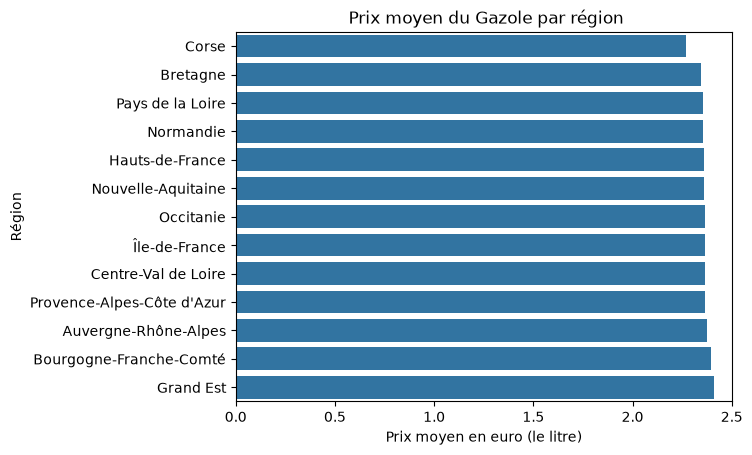

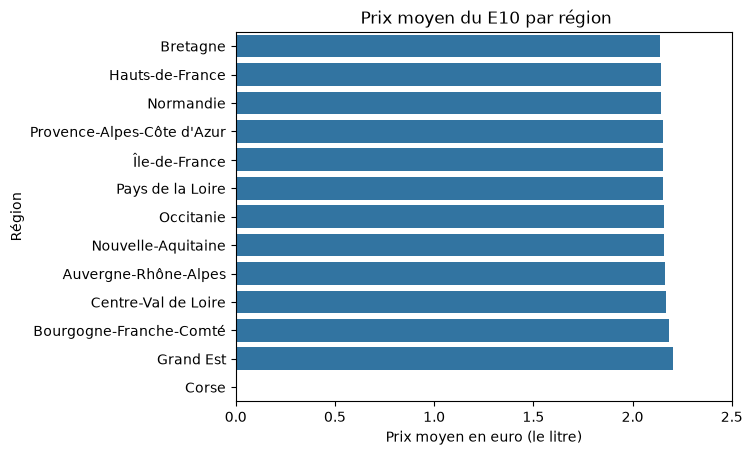

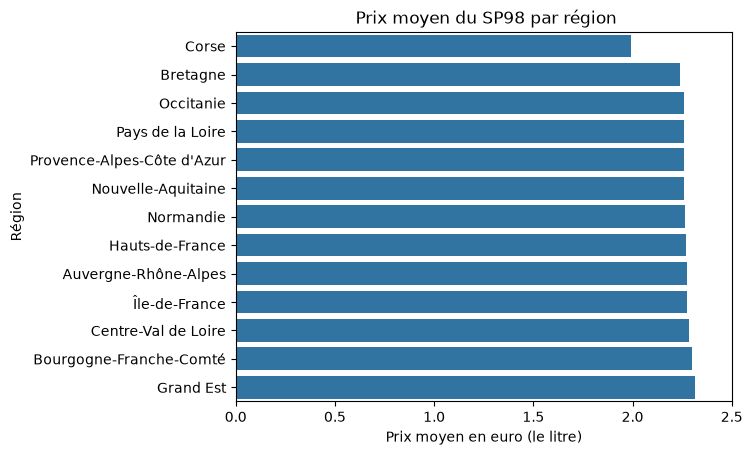

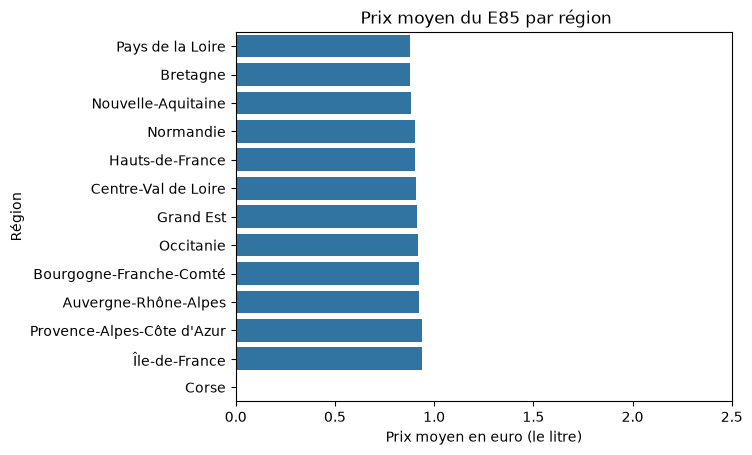

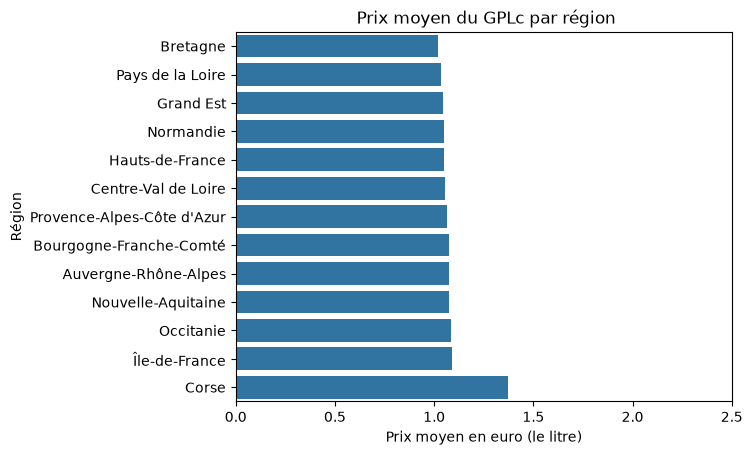

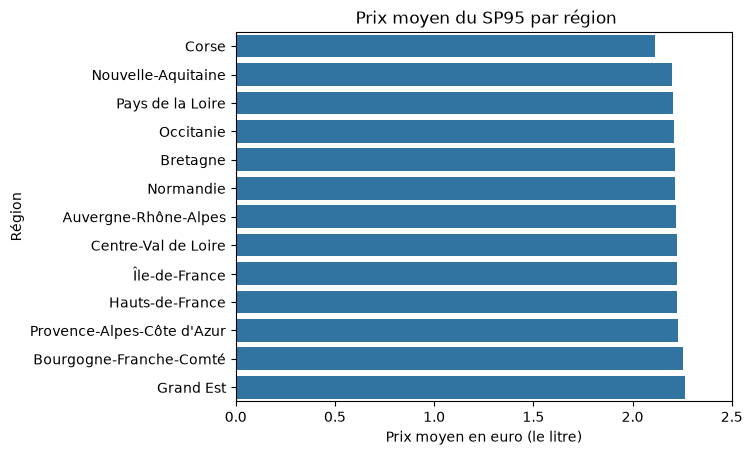

L'ecart type maximal est 0.123483307490473, correspondant au SP98


In [62]:
## ETUDE DES PRIX DES CARBURANTS SELON LES REGIONS ## 

import matplotlib.pyplot as plt
import seaborn as sns

for carburant in Carburants : 
    df_carburant = df.groupby('Région')[carburant].mean().sort_values()
    sns.barplot(x=df_carburant.values, y=df_carburant.index)   ## Cette ligne permet de gérer les diagrammes batons : les y sont les régions et les x les prix
    plt.title(f" Prix moyen du {carburant} par région")
    plt.xlabel('Prix moyen en euro (le litre)')
    plt.xlim([0, 2.5])
    plt.show()


''' On remarque certaines choses : 
    - Pour le Gazole, E10, SP98, SP95 c'est le Grand Est la région la plus chere 
    - Pour le GLPc c'est la Corse 
    - Pour le E85 c'est l'Ile de France 

    Sauf pour le SP98, l'ecart type est assez faible entre les différentes Régions"
'''
## Calcul de l'écart type : 
ecart_type = []
for carburant in Carburants : 
    ecart_type.append(df[carburant].std(skipna=True))

idx_max = ecart_type.index(max(ecart_type))

print(f"L'ecart type maximal est {max(ecart_type)}, correspondant au {Carburants[idx_max]}")


In [76]:
## Funfact sur la ville la moins chère et la plus chère selon le carburant ##

tab = []
for carburant in Carburants : 
    ville_carburant_moy = df.dropna(subset=[carburant]).groupby('Ville')[carburant].mean().sort_values() 

## On doit enlever les valeurs Nan, sinon elles apparaissent comme les valeurs les plus petites donc on aurait que des Nan en prix de la ville la moins chère 
    
   
    ville_min = ville_carburant_moy.idxmin()
    prix_min = ville_carburant_moy.min()
                                                    ## On récupère les villes avec le prix le plus bas ainsi que celles avec le prix le plus hauts
                                                    ## et leur prix associé
    ville_max = ville_carburant_moy.idxmax()
    prix_max = ville_carburant_moy.max()

    tab.append({'Carburant':carburant,'Ville moins chère':ville_min,'Prix min':round(prix_min,3),'Ville plus chère':ville_max,'Prix max':round(prix_max,3)})


df_tab = pd.DataFrame(tab) ## on transforme tab en tableau pour plus de lisibilité
print(df_tab)

'''Le carburant est bien chère à Frazé !!!!!! '''

  Carburant   Ville moins chère  Prix min       Ville plus chère  Prix max
0    Gazole          Fleurville     1.990            L'Île-d'Yeu     2.829
1       E10             Haspres     1.989                  Frazé     2.599
2      SP98             Épuisay     1.980                  Frazé     2.779
3       E85  Ambarès-et-Lagrave     0.741              Cauterets     2.249
4      GPLc        Châteaugiron     0.899  Chasseneuil-du-Poitou     1.600
5      SP95        Noisy-le-Sec     1.849              Cléguérec     2.740
